The "model training" part; moves the current lead-in overviewing Hillenbrand data to this section, doing the exploratin there and assuming vowels etc. have been covered already. Then, we'll train the CNN with Torch; discuss; and run a handful of classical models, using both sklearn and NNet equivalents in Torch.

Ends with a broader discussion of formant normalization, its assumptions (uniform scaling of formant values across speakers), bridging to the math below.

## Vowels, Formants ...

Goal here is to teach CNNs for image classification in the context of audio classification. Specifically, we'll describe the technique of converting audio signals to spectrograms; apply it to human vowels from the Hillenbrand data set; and analyze its performance to see that it does well on a specific subset of data, with poorer performance on another. Studying the error class reveals underlying structure that motivates studying the source-filter model.

## The Task

## The Methodology

#### Convolutional Neural Networks

### Hillenbrand Data

In [2]:
import glob
import os
import IPython.display as ipd

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import librosa as lb
import scipy as sp
import scipy.signal
import sounddevice as sd
import torch
import torchaudio

The Hillenbrand dataset...

Audio data is split across three categories: men, women, and children. Each directory contains WAV files, so we can manipulate the raw audio.

In [4]:
!ls -l data/hillenbrand/kids | head -n 5

total 21960
-rw-rw-rw-  1 peleke  staff  13400 May 13  2002 b01ae.wav
-rw-rw-rw-  1 peleke  staff  12728 May 13  2002 b01ah.wav
-rw-rw-rw-  1 peleke  staff  14574 May 13  2002 b01aw.wav
-rw-rw-rw-  1 peleke  staff  14284 May 13  2002 b01eh.wav
ls: stdout: Broken pipe


We're training two kinds of models:

- **Classical ML**, via logistic regression and SVM on the tabulatd formant frequency data
- **CNN**, trained on Mel spectrograms generated from each recording.s

We'll start by loading the tabular data, contained in the following files:

- `vowdata.dat`: Contains formant frequency measurements For F1-F4 at Steady State and 20/50/80% intensity.
- `iddata.dat`: Contains label data, specifying which vowels listeners assigned to each recording.
- `misid.dat`: A subset of `iddata.dat` that contains vowels misidentified by listeners.
- `timedata.dat`: Identifies the start, end, and steady-state recording times for each row in `vowdata`; `center1` and `center2` refer to the separate times two different listeners measured the formant's steady state.

Workflow will be:

- Merge `vowdata`, `iddata`, and `misid`
- Create a PyTorch DataSet to wrap our WAV files
- Load `timedata`, trim excess audio, and generate Mel spectrograms

Let's start with `vowdata.dat`. It's a text file, not a CSV, so we'll need to do some manual parsing.

The header contains a description of the file contents, with the data following below. Let's take a look.

In [5]:
!head -n 35 data/hillenbrand/vowdata.dat

(c) 1995 James Hillenbrand

Filenames:

character 1:     m=man, w=woman, b=boy, g=girl
characters 2-3:  talker number
characters 4-5:  vowel (ae="had", ah="hod", aw="hawed", eh="head", er="heard",
                        ei="haid", ih="hid", iy="heed", oa=/o/ as in "boat",
                        oo="hood", uh="hud", uw="who'd")

col1:  filename
col2:  duration in msec
col3:  f0 at "steady state"
col4:  F1 at "steady state"
col5:  F2 at "steady state"
col6:  F3 at "steady state"
col7:  F4 at "steady state"
col8:  F1 at 20% of vowel duration
col9:  F2 at 20% of vowel duration
col10: F3 at 20% of vowel duration
col11: F1 at 50% of vowel duration
col12: F2 at 50% of vowel duration
col13: F3 at 50% of vowel duration
col14: F1 at 80% of vowel duration
col15: F2 at 80% of vowel duration
col16: F3 at 80% of vowel duration

Note: An entry of zero means that the formant was not measurable.

  1    2   3    4    5    6    7    8    9   10    11  12   13    14  15   16
m01ae 323 174  663 2012 265

Alright; let's get set up.

#### Representing in Code

We create a DataFrame as follows.

In [6]:
# speaker category
speaker_categories = {
    'm': 'man',
    'w': 'woman',
    'b': 'boy',
    'g': 'girl',
}

In [7]:
columns = [
    'filename',
    'duration_ms',
    'f0_ss',
    'f1_ss',
    'f2_ss',
    'f3_ss',
    'f4_ss',
    'f1_20',
    'f2_20',
    'f3_20',
    'f1_50',
    'f2_50',
    'f3_50',
    'f1_80',
    'f2_80',
    'f3_80',
]

Let's convert that vowel list into a proper IPA equivalence chart. This data specifically pertains to American English, so the IPA should be fairly close.

| Code | Word | IPA | Description |
| :--- | :--- | :--- | :--- |
| **ae** | had | **/æ/** | Near-open front unrounded vowel |
| **ah** | hod | **/ɑ/** | Open back unrounded vowel |
| **aw** | hawed | **/ɔ/** | Open-mid back rounded vowel |
| **eh** | head | **/ɛ/** | Open-mid front unrounded vowel |
| **er** | heard | **/ɝ/** | R-colored mid central vowel |
| **ei** | haid | **/e/** | Close-mid front vowel (often transcribed as diphthong **/eɪ/**) |
| **ih** | hid | **/ɪ/** | Near-close near-front unrounded vowel |
| **iy** | heed | **/i/** | Close front unrounded vowel |
| **oa** | boat | **/o/** | Close-mid back vowel (often transcribed as diphthong **/oʊ/**) |
| **oo** | hood | **/ʊ/** | Near-close near-back rounded vowel |
| **uh** | hud | **/ʌ/** | Open-mid back unrounded vowel |
| **uw** | who'd | **/u/** | Close back rounded vowel |

[Read this](https://www.researchgate.net/publication/231929195_American_English_Southern_Michigan)

In [8]:
# vowel inventory: vowel, IPA
vowels_map = {
    'ae': 'ɑ',
    'ah': 'ɑ',
    'aw': 'ɔ',
    'eh': 'ɛ',
    'er': 'ɝ',
    'ei': 'e',
    'ih': 'ɪ',
    'iy': 'i',
    'oa': 'o',
    'oo': 'ʊ',
    'uh': 'ʌ',
    'uw': 'u',
}

Now we can load the DataFrame.

In [9]:
df = pd.read_csv(
    'data/hillenbrand/vowdata.dat',
    sep=r"\s+",
    header=None,
    names=columns,
    skiprows=30,
)

In [10]:
df.head()

,filename,duration_ms,f0_ss,f1_ss,f2_ss,f3_ss,f4_ss,f1_20,f2_20,f3_20,f1_50,f2_50,f3_50,f1_80,f2_80,f3_80
0,m01ae,323,174,663,2012,2659,3691,669,2008,2671,671,1992,2659,685,1773,2680
1,m02ae,250,102,628,1871,2477,3489,627,1871,2456,636,1881,2455,628,1793,2451
2,m03ae,344,99,605,1812,2570,0,608,1812,2572,618,1789,2618,632,1708,2693
3,m04ae,312,124,627,1910,2488,3463,629,1882,2460,720,1750,2435,757,1563,2527
4,m06ae,254,115,647,1864,2561,3506,642,1866,2557,666,1829,2499,689,1696,2556


Perfect; let's add a path column as well.

In [11]:
paths = []

In [12]:
for filename in df['filename']:
    category = filename[0]
    if category == 'm':
        path = f'data/hillenbrand/men/{filename}'
    elif category in ['b', 'g']:
        path = f'data/hillenbrand/kids/{filename}'
    elif category == 'w':
        path = f'data/hillenbrand/women/{filename}'
    else:
        raise ValueError("huh-what?")
    paths.append(path)

In [13]:
paths[:5]

['data/hillenbrand/men/m01ae',
 'data/hillenbrand/men/m02ae',
 'data/hillenbrand/men/m03ae',
 'data/hillenbrand/men/m04ae',
 'data/hillenbrand/men/m06ae']

In [14]:
df['path'] = paths

In [15]:
df.head()

,filename,duration_ms,f0_ss,f1_ss,f2_ss,f3_ss,f4_ss,f1_20,f2_20,f3_20,f1_50,f2_50,f3_50,f1_80,f2_80,f3_80,path
0,m01ae,323,174,663,2012,2659,3691,669,2008,2671,671,1992,2659,685,1773,2680,data/hillenbrand/men/m01ae
1,m02ae,250,102,628,1871,2477,3489,627,1871,2456,636,1881,2455,628,1793,2451,data/hillenbrand/men/m02ae
2,m03ae,344,99,605,1812,2570,0,608,1812,2572,618,1789,2618,632,1708,2693,data/hillenbrand/men/m03ae
3,m04ae,312,124,627,1910,2488,3463,629,1882,2460,720,1750,2435,757,1563,2527,data/hillenbrand/men/m04ae
4,m06ae,254,115,647,1864,2561,3506,642,1866,2557,666,1829,2499,689,1696,2556,data/hillenbrand/men/m06ae


We can map the filename out into features.

In [16]:
a = 'm01ae'

In [17]:
a[3:]

'ae'

In [18]:
categories, talker_numbers, vowels = [], [], []

In [19]:
for filename in df['filename']:
    category = categories.append(filename[0])
    talker_number = talker_numbers.append(filename[1:3])
    vowel = vowels.append(filename[3:])

In [20]:
df['category'] = categories
df['speaker_id'] = talker_numbers
df['vowel'] = vowels

Let's reorder columns.

In [21]:
metadata_cols = ['filename', 'category', 'speaker_id', 'vowel', 'path']
acoustic_cols = [col for col in columns if col != 'filename']
df = df[metadata_cols + acoustic_cols]

In [22]:
df.head()

,filename,category,speaker_id,vowel,path,duration_ms,f0_ss,f1_ss,f2_ss,f3_ss,f4_ss,f1_20,f2_20,f3_20,f1_50,f2_50,f3_50,f1_80,f2_80,f3_80
0,m01ae,m,01,ae,data/hillenbrand/men/m01ae,323,174,663,2012,2659,3691,669,2008,2671,671,1992,2659,685,1773,2680
1,m02ae,m,02,ae,data/hillenbrand/men/m02ae,250,102,628,1871,2477,3489,627,1871,2456,636,1881,2455,628,1793,2451
2,m03ae,m,03,ae,data/hillenbrand/men/m03ae,344,99,605,1812,2570,0,608,1812,2572,618,1789,2618,632,1708,2693
3,m04ae,m,04,ae,data/hillenbrand/men/m04ae,312,124,627,1910,2488,3463,629,1882,2460,720,1750,2435,757,1563,2527
4,m06ae,m,06,ae,data/hillenbrand/men/m06ae,254,115,647,1864,2561,3506,642,1866,2557,666,1829,2499,689,1696,2556


Splendid. Now, let's address this note in the metadata:

> Note: An entry of zero means that the formant was not measurable.

I.e., 0 is an explicit indication of a measurement error. Let's see where these occur.

In [23]:
(df == 0).sum()

filename         0
category         0
speaker_id       0
vowel            0
path             0
duration_ms      0
f0_ss            0
f1_ss            0
f2_ss           10
f3_ss           41
f4_ss          243
f1_20            0
f2_20           10
f3_20           39
f1_50            0
f2_50           13
f3_50           46
f1_80            0
f2_80            3
f3_80           41
dtype: int64

In [24]:
len(df)

1668

In [25]:
243 / 1668

0.14568345323741008

Roughly 14% of the steady-state format 4 data was unmeasurable. Not great, but F4 is poorly represented, anyway; might not be a terrible loss.

In any case, let's mark these as `np.nan` so we don't confuse the model.

In [26]:
df.replace(0, np.nan, inplace=True)

,filename,category,speaker_id,vowel,path,duration_ms,f0_ss,f1_ss,f2_ss,f3_ss,f4_ss,f1_20,f2_20,f3_20,f1_50,f2_50,f3_50,f1_80,f2_80,f3_80
0,m01ae,m,01,ae,data/hillenbrand/men/m01ae,323,174,663,2012.0,2659.0,3691.0,669,2008.0,2671.0,671,1992.0,2659.0,685,1773.0,2680.0
1,m02ae,m,02,ae,data/hillenbrand/men/m02ae,250,102,628,1871.0,2477.0,3489.0,627,1871.0,2456.0,636,1881.0,2455.0,628,1793.0,2451.0
2,m03ae,m,03,ae,data/hillenbrand/men/m03ae,344,99,605,1812.0,2570.0,NaN,608,1812.0,2572.0,618,1789.0,2618.0,632,1708.0,2693.0
3,m04ae,m,04,ae,data/hillenbrand/men/m04ae,312,124,627,1910.0,2488.0,3463.0,629,1882.0,2460.0,720,1750.0,2435.0,757,1563.0,2527.0
4,m06ae,m,06,ae,data/hillenbrand/men/m06ae,254,115,647,1864.0,2561.0,3506.0,642,1866.0,2557.0,666,1829.0,2499.0,689,1696.0,2556.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1663,g17uw,g,17,uw,data/hillenbrand/kids/g17uw,245,236,490,2179.0,3131.0,4420.0,482,2163.0,3097.0,491,2044.0,3097.0,500,1912.0,3056.0
1664,g18uw,g,18,uw,data/hillenbrand/kids/g18uw,315,214,435,1829.0,3316.0,4536.0,432,1836.0,3378.0,435,1684.0,3276.0,444,1716.0,3229.0
1665,g19uw,g,19,uw,data/hillenbrand/kids/g19uw,192,243,497,1334.0,3067.0,3928.0,491,1335.0,3067.0,492,1402.0,3044.0,478,1490.0,2961.0
1666,g20uw,g,20,uw,data/hillenbrand/kids/g20uw,248,248,498,1740.0,3291.0,4500.0,496,1728.0,3327.0,467,1665.0,3312.0,450,1821.0,3383.0


We need to do preprocessing and such—specifically, normalize duration and formant frequencies—but this is ready to prepare for our classical classification models.

#### Loading `iddata` and `misid`

Let's load labels...

In [27]:
!head -n 21 data/hillenbrand/iddata.dat

col1 = Filename
col2 = Percent correct ID
col3 = Number (out of 20) heard as iy
col4 = Number (out of 20) heard as ih
col5 = Number (out of 20) heard as ei
col6 = Number (out of 20) heard as eh
col7 = Number (out of 20) heard as ae
col8 = Number (out of 20) heard as ah
col9 = Number (out of 20) heard as aw
col10= Number (out of 20) heard as oa
col11= Number (out of 20) heard as oo
col12= Number (out of 20) heard as uw
col13= Number (out of 20) heard as uh
col14= Number (out of 20) heard as er
col15= Signal heard predominately as this vowel

Note: An asterisk to the far right means that the majority vote was
      for a vowel other than that intended by the talker.

Filename    %ID   iy  ih  ei  eh  ae  ah  aw  oa  oo  uw  uh  er Vote
m01ae.w     95.0   0   0   0   1  19   0   0   0   0   0   0   0  ae


In [28]:
columns_iddata = [
    'filename',
    '%_id',
    'iy',
    'ih',
    'ei',
    'eh',
    'ae',
    'ah',
    'aw',
    'oa',
    'oo',
    'uw',
    'uh',
    'er',
    'vote',
    'misid',
]

In [29]:
df_iddata = pd.read_csv(
    'data/hillenbrand/iddata.dat',
    sep=r"\s+",
    header=None,
    names=columns_iddata,
    skiprows=20,
)

Each row shows how many votes each vowel received from listeners during labeling. 

In [30]:
df_iddata.head()

,filename,%_id,iy,ih,ei,eh,ae,ah,aw,oa,oo,uw,uh,er,vote,misid
0,m01ae.w,95.0,0,0,0,1,19,0,0,0,0,0,0,0,ae,NaN
1,m01ah.w,95.0,0,0,0,0,0,19,1,0,0,0,0,0,ah,NaN
2,m01aw.w,95.0,0,0,0,0,0,1,19,0,0,0,0,0,aw,NaN
3,m01eh.w,100.0,0,0,0,20,0,0,0,0,0,0,0,0,eh,NaN
4,m01ei.w,100.0,0,0,20,0,0,0,0,0,0,0,0,0,ei,NaN


In [31]:
df_iddata.describe()['%_id']

count    1668.000000
mean       94.640288
std        12.425765
min         0.000000
25%        95.000000
50%       100.000000
75%       100.000000
max       100.000000
Name: %_id, dtype: float64

Listeners agree across most of our rows.

Convert `misid` to a boolean column, so it's `False` if there's no asterisk (instead of `NaN`) and `True` otherwise.

In [32]:
df_iddata['misid'] = df_iddata['misid'].notna()

Next, we load data corresponding to misidentified vowels; these are instances of vowels that listeners guessed wrong.

In [33]:
!head -n 5 data/hillenbrand/misid.dat

m04eh.w     30.0   0   0   0   6  14   0   0   0   0   0   0   0  ae *
m16ah.w     25.0   0   0   0   0   0   5   1   0   0   0  14   0  uh *
m22aw.w     45.0   0   0   0   0   0  11   9   0   0   0   0   0  ah *
m24aw.w     45.0   0   0   0   0   0  11   9   0   0   0   0   0  ah *
m29aw.w     40.0   0   0   0   1   0  11   8   0   0   0   0   0  ah *


In [34]:
df_misid = pd.read_csv(
    'data/hillenbrand/misid.dat',
    sep=r"\s+",
    header=None,
    names=columns_iddata,
    skiprows=0,
)

In [35]:
df_misid.head()

,filename,%_id,iy,ih,ei,eh,ae,ah,aw,oa,oo,uw,uh,er,vote,misid
0,m04eh.w,30.0,0,0,0,6,14,0,0,0,0,0,0,0,ae,*
1,m16ah.w,25.0,0,0,0,0,0,5,1,0,0,0,14,0,uh,*
2,m22aw.w,45.0,0,0,0,0,0,11,9,0,0,0,0,0,ah,*
3,m24aw.w,45.0,0,0,0,0,0,11,9,0,0,0,0,0,ah,*
4,m29aw.w,40.0,0,0,0,1,0,11,8,0,0,0,0,0,ah,*


All `misid` values here are `True`, so might as well force that.

In [36]:
df_misid['misid'] = True

We'll use this to guide evaluation of the final model.

#### Creating Labels

Let's convert the `iddata` DataFrame into a proper set of `y` labels.

In [37]:
df_iddata.head()

,filename,%_id,iy,ih,ei,eh,ae,ah,aw,oa,oo,uw,uh,er,vote,misid
0,m01ae.w,95.0,0,0,0,1,19,0,0,0,0,0,0,0,ae,False
1,m01ah.w,95.0,0,0,0,0,0,19,1,0,0,0,0,0,ah,False
2,m01aw.w,95.0,0,0,0,0,0,1,19,0,0,0,0,0,aw,False
3,m01eh.w,100.0,0,0,0,20,0,0,0,0,0,0,0,0,eh,False
4,m01ei.w,100.0,0,0,20,0,0,0,0,0,0,0,0,0,ei,False


In [38]:
subcols = [c for c in df_iddata.columns if c not in ['%_id', 'vote', 'misid', 'filename']]

In [39]:
# collapse to highest-confidence vote
y = df_iddata[subcols].idxmax(axis=1)

We still need to scale our `vowdata`, but we have what we need to prepare the classical classifier.

#### Raw Audio & Mel Spectrograms

Before we grab the audio, let's load `timedata.dat`, which gives us the following data about each recording in milliseconds:

- `start`
- `end`
- `center1` (steady-state vowel time from judge 1)
- `center2` (steady-state vowel time from judge 2)

These will allow us to trim onset and coda from the vowel recordings before generating spectrograms for the CNN.

In [40]:
columns_timedata = [
    'filename',
    'start',
    'end',
    'center1',
    'center2',
]

In [41]:
df_timedata = pd.read_csv(
    'data/hillenbrand/timedata.dat',
    sep=r"\s+",
    header=None,
    names=columns_timedata,
    skiprows=6,
)

In [42]:
df_timedata.head()

,filename,start,end,center1,center2
0,m01ae,177.3,500.4,304.0,297.0
1,m02ae,132.0,382.0,198.0,240.0
2,m03ae,118.0,462.0,162.0,181.0
3,m04ae,96.0,408.0,130.0,169.0
4,m06ae,71.0,325.0,113.0,134.0


Next, we load the raw audio data into the PyTorch DataSet that we'll need to generate spectrograms and train the CNN...But first, let's look at the recordings.

#### Inspecting the Hillenbrand Recordings

Loading the first...

In [43]:
example = df['path'].iloc[0]
example

'data/hillenbrand/men/m01ae'

In [44]:
audio, sr = lb.load(f'{example}.wav', sr=None)

In [45]:
# sampling rate; n.b., can only represent signals up to 8k 
sr

16000

In [46]:
ipd.Audio(audio, rate=sr)

Let's sanity-check the `timedata` contents; we'll plot the waveform and overlay the start/end times.

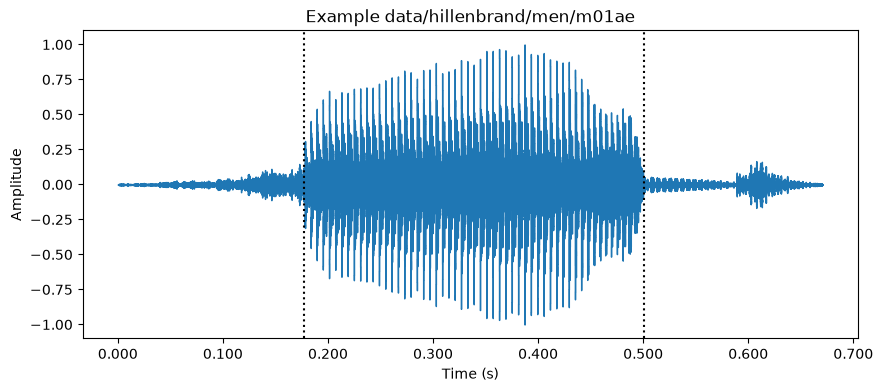

In [47]:
# Create the plot
fig, ax = plt.subplots(figsize=(10, 4))
lb.display.waveshow(audio, sr=sr, ax=ax)

# Add labels and show
ax.set(title=f'Example {example}', xlabel="Time (s)", ylabel="Amplitude")
plt.axvline(x=df_timedata['start'].iloc[0] / 1000, color='black', linestyle='dotted')
plt.axvline(x=df_timedata['end'].iloc[0] / 1000, color='black', linestyle='dotted')
plt.show()

This is just the **waveform**; the amplitude of the wave over time. Vertical lines indicate the start and end of the vowel, isolated from onset and coda consonants.

In [48]:
df.columns

Index(['filename', 'category', 'speaker_id', 'vowel', 'path', 'duration_ms',
       'f0_ss', 'f1_ss', 'f2_ss', 'f3_ss', 'f4_ss', 'f1_20', 'f2_20', 'f3_20',
       'f1_50', 'f2_50', 'f3_50', 'f1_80', 'f2_80', 'f3_80'],
      dtype='str')

...It's not very useful, is it?

#### Formant Normalization

We're almost there—I promise. In fact, this is all we need to train our models; we could technically proceed.

...But that would be a mistake, as I'm sure your newly acquired linguistic instincts are bellowing.

Our goal is to classify vowels, given their formant values; or, in the case of the CNN, their Mel spectrograms, which should contain the same information.

The naive approach is to proceed with a standard train/test split. But consider what's in our dataset: Vowel utterances, collected from different speakers, across different age groups, from different categories of biological sex.

Considering age, sex, and other often-irrelevant demographic features demands a justification. But in this case, it's actually forced. Vocal tract lengths for men, women, and children are as follows:

- **Men**: ...
- **Women**: ...
- **Children**: ...

Refer

- [Vowel Acoustic Space Development in Children](https://pmc.ncbi.nlm.nih.gov/articles/PMC2597712/#R83)
- [Control Methods Used in the Study of Vowels](https://www.ee.columbia.edu/~dpwe/papers/PetB52-vowels.pdf)

These differences in vocal tract length, as well as mass of the vocal cords, have considerable influence on the fundamental frequency of one's voice (heavier vocal cords produce a lower fundamental frequency), as well as its timbre (the character of formants).

It's not an immaterial detail: Children, for instance, [have higher fundamental and formant frequencies](https://pmc.ncbi.nlm.nih.gov/articles/PMC4976617/), which raises unique signal processing challenges relative to voices with lower fundamentals.

We need to train the model in a manner that ensures it learns to distinguish formants _within the relative context_—i.e., in the context of the "formant space" represented by the corresponding speaker within the dataset—rather than mistakenly assume that the wide variance in, e.g., F0 values is in fact reflective of _formants_ rather than the indiviuals producing them. 

There are two sides to this:

- **Split on Speaker**: Ensure each of the model's batches is drawn from its speaker's "formant space".
- **Formant normalization**: We can normalize formant frequencies directly with statistical techniques; one popular option, called [Lobanov's method](https://www.isca-archive.org/interspeech_2021/heeringa21_interspeech.pdf), simply maps each formant value to its (speaker) z-score, which should feel familiar.

The consensus, as noted by [Dr Barlaz's overview](https://marissabarlaz.github.io/portfolio/vowelnormalization/) of [R's vowels package](https://cran.r-project.org/web/packages/vowels/refman/vowels.html), following [Adank's 2004 analysis of formant normalization methods](https://pubmed.ncbi.nlm.nih.gov/15478440/) is that Lobanove performs best.

We'll discuss other common options below, but only briefly.

- Lobanov’s Method (Z-Score): Subtracts a speaker's mean formant frequency from the raw formant value and divides by the standard deviation, converting values into z-scores (mean = 0, SD = 1).
- Nearey’s Methods: Log-mean or log-mean-standardized transformations applied either intrinsically or extrinsically across the speaker's vowel space.
- Watt & Fabricius Method: Relies on the geometric centroid of a speaker's triangular vowel space (using corner vowels like /i, a, u/) to scale formant values relative to overall vowel space size.
- [Delta-F (Δ F) / Vocal Tract Length Normalization (VTLN)](https://www.journal-labphon.org/article/id/6268/): Estimates average formant spacing (\(F_1 = \frac{1}{2}\Delta F, F_2 = 1\frac{1}{2}\Delta F\), etc.) to directly model and remove physical vocal tract length differences.s

First, let's take a look at how formant frequencies vary across speakers.

In [161]:
# TODO: reproduce F1/F2 chart

TODO

- F1/F2 vowel space
- Vowel Quality: Backness, etc., 
- Recovery of IPA chart
- Vowels group across broad ranges of acoustic properties, despite being heard identically by listeners
  - This is **talker normalization**; formant normaliation does something like this for the machine
  - We _do_ have to be careful; we're by definition destroying individual variation that very well may be culturally or idiosyncratically meaningful

TODO

- Extrinsic vs intrinsic normalization
- Neary and Lobanov head-to-head (similar)
- Rest (overview)

We'll use the Lobanov-transformed data for both of our models; and make sure to remember to split on speaker in training.

With that—we're finally done. That's all we need.

Let's train some models.

### Model Training

We'll take two approaches:

- **Classical ML**: We can train traditional classifiers—like SVM, Logistic Regression, etc.—against the data in the spreadsheet. This is our baseline.
- **Convolutional Neural Nets**: We can convert each vowel into its Mel spectrogram, and use a CNN to distinguish them _visually_.

We know in advance the latter is a more powerful technique, but we'll run both for comparison's sake.

CNNs are more exciting, though, so let's start there.

f0_ss: 174
f1_ss: 663
f2_ss: 2012.0
f3_ss: 2659.0
f4_ss: 3691.0


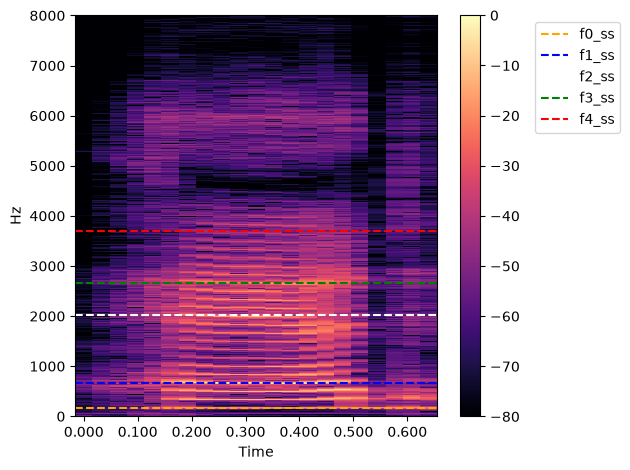

In [224]:
D = lb.stft(audio)  # STFT of y
S_db = lb.amplitude_to_db(np.abs(D), ref=np.max)

plt.figure()
lb.display.specshow(S_db, sr=sr, x_axis="time", y_axis="hz")

cols = [c for c in df.columns if c.endswith(r"ss") and c!= 'filename']
colors = ['red', 'green', 'white', 'blue', 'orange']
for c in cols:
    val = df[c].iloc[0]
    print(f'{c}: {val}')
    plt.axhline(y=val, color=colors.pop(), linestyle='--', label=c)

plt.legend(bbox_to_anchor=(1.25, 1), loc='upper left')
plt.colorbar()
plt.tight_layout()
plt.show()

Not great on the eyes, but it's a good gut check.

```
# in hz
f1_ss: 663
f0_ss: 174
f2_ss: 2012.0
f3_ss: 2659.0
f4_ss: 3691.0
```